### Iris Flower Classification

In [ ]:
# Import necessary libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

In [ ]:
# Load the iris dataset
iris = load_iris()

# Create a DataFrame for better data handling
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['species'] = iris.target

# Display the first few rows of the dataset
print(df.head())

In [ ]:
# Define features (X) and target (y)
X = df.drop('species', axis=1) # All columns except 'species'
y = df['species']             # The 'species' column

# Split the data into training and testing sets
# We use 80% of the data for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
#  Train the Classifier
# Create an instance of the Logistic Regression model
model = LogisticRegression(max_iter=200)

# Train the model using the training data
model.fit(X_train, y_train)

In [ ]:
# 5: Make Predictions and Evaluate the Model
# Make predictions on the test data
y_pred = model.predict(X_test)

# Calculate and print the accuracy score
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

# Print the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Dataset shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']

First 5 rows of the dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species species_name  
0        0       setosa  
1        0       setosa  
2        0       setosa  
3        0       setosa  
4        0       setosa  

=== Exploratory Data Analysis ===

Dataset statistics:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000    

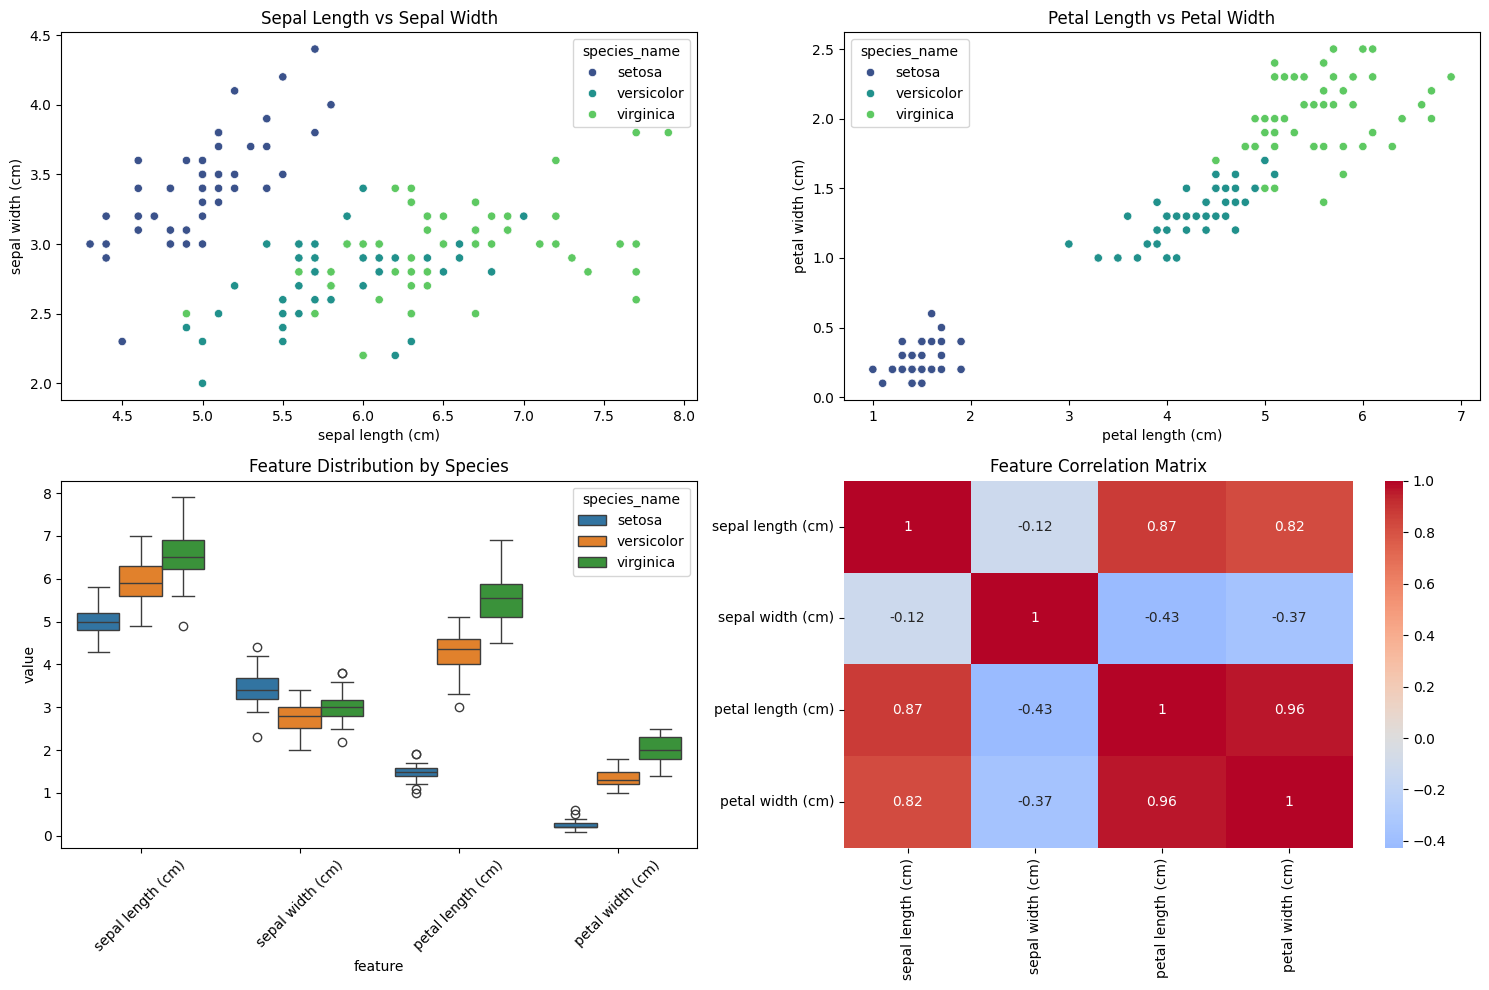


Training set size: 120
Test set size: 30

=== Model Evaluation ===
Logistic Regression:
  Test Accuracy: 0.9333
  CV Accuracy: 0.9583 (±0.0264)

SVM:
  Test Accuracy: 0.9667
  CV Accuracy: 0.9667 (±0.0312)

K-Nearest Neighbors:
  Test Accuracy: 0.9333
  CV Accuracy: 0.9667 (±0.0312)

Decision Tree:
  Test Accuracy: 0.9333
  CV Accuracy: 0.9417 (±0.0204)

Random Forest:
  Test Accuracy: 0.9000
  CV Accuracy: 0.9500 (±0.0167)

Best model: SVM with accuracy 0.9667

=== Detailed Evaluation of SVM ===
Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Confusion Matrix:


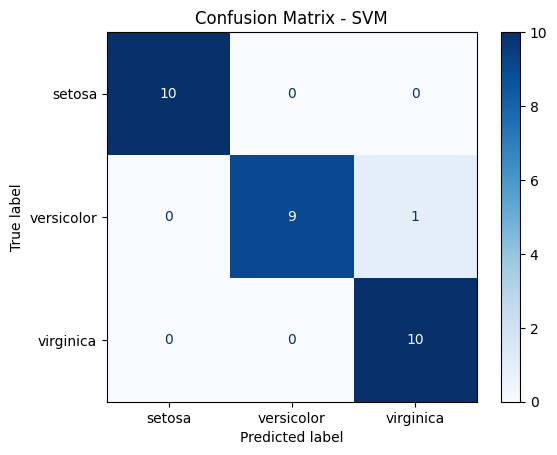


=== Example Prediction ===


AttributeError: This 'SVC' has no attribute 'predict_proba'

In [1]:
# Example 2 of a simple ML classifier using the Iris dataset.
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, 
                           confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV

# Set random seed for reproducibility
np.random.seed(42)

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

print("Dataset shape:", X.shape)
print("Feature names:", feature_names)
print("Target names:", target_names)

# Create a DataFrame for better visualization
df = pd.DataFrame(X, columns=feature_names)
df['species'] = y
df['species_name'] = [target_names[i] for i in y]

print("\nFirst 5 rows of the dataset:")
print(df.head())

# Exploratory Data Analysis
print("\n=== Exploratory Data Analysis ===")

# Basic statistics
print("\nDataset statistics:")
print(df.describe())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Class distribution
print("\nClass distribution:")
print(df['species_name'].value_counts())

# Data Visualization
plt.figure(figsize=(15, 10))

# Pairplot
plt.subplot(2, 2, 1)
sns.scatterplot(data=df, x='sepal length (cm)', y='sepal width (cm)', 
                hue='species_name', palette='viridis')
plt.title('Sepal Length vs Sepal Width')

plt.subplot(2, 2, 2)
sns.scatterplot(data=df, x='petal length (cm)', y='petal width (cm)', 
                hue='species_name', palette='viridis')
plt.title('Petal Length vs Petal Width')

# Box plots
plt.subplot(2, 2, 3)
df_melted = df.melt(id_vars=['species_name'], 
                   value_vars=feature_names, 
                   var_name='feature', 
                   value_name='value')
sns.boxplot(data=df_melted, x='feature', y='value', hue='species_name')
plt.xticks(rotation=45)
plt.title('Feature Distribution by Species')

# Correlation heatmap
plt.subplot(2, 2, 4)
correlation_matrix = df[feature_names].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Feature Correlation Matrix')

plt.tight_layout()
plt.show()

# Data Preprocessing
# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

# Model Training and Evaluation
models = {
    'Logistic Regression': LogisticRegression(max_iter=200),
    'SVM': SVC(),
    'K-Nearest Neighbors': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier()
}

results = {}

print("\n=== Model Evaluation ===")
for name, model in models.items():
    # Train the model
    model.fit(X_train_scaled, y_train)
    
    # Make predictions
    y_pred = model.predict(X_test_scaled)
    
    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)
    
    # Cross-validation score
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5)
    
    results[name] = {
        'model': model,
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }
    
    print(f"{name}:")
    print(f"  Test Accuracy: {accuracy:.4f}")
    print(f"  CV Accuracy: {cv_scores.mean():.4f} (±{cv_scores.std():.4f})")
    print()

# Find the best model
best_model_name = max(results, key=lambda x: results[x]['accuracy'])
best_model = results[best_model_name]['model']

print(f"Best model: {best_model_name} with accuracy {results[best_model_name]['accuracy']:.4f}")

# Detailed evaluation of the best model
print(f"\n=== Detailed Evaluation of {best_model_name} ===")

# Make predictions with best model
y_pred_best = best_model.predict(X_test_scaled)

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred_best, target_names=target_names))

# Confusion matrix
print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

# Hyperparameter Tuning (for the best model)
if best_model_name == 'Random Forest':
    param_grid = {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 10, 20, 30],
        'min_samples_split': [2, 5, 10]
    }
    
    grid_search = GridSearchCV(
        RandomForestClassifier(),
        param_grid,
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )
    
    grid_search.fit(X_train_scaled, y_train)
    
    print(f"Best parameters: {grid_search.best_params_}")
    print(f"Best cross-validation score: {grid_search.best_score_:.4f}")
    
    # Use the best estimator
    best_model = grid_search.best_estimator_

# Make predictions on new data
def predict_iris(model, scaler, sepal_length, sepal_width, petal_length, petal_width):
    """
    Predict iris species based on measurements
    """
    # Create input array
    input_data = np.array([[sepal_length, sepal_width, petal_length, petal_width]])
    
    # Scale the input
    input_scaled = scaler.transform(input_data)
    
    # Make prediction
    prediction = model.predict(input_scaled)
    probabilities = model.predict_proba(input_scaled)
    
    return target_names[prediction[0]], probabilities[0]

# Example prediction
print("\n=== Example Prediction ===")
sample_measurements = [5.1, 3.5, 1.4, 0.2]  # Setosa example
predicted_species, probabilities = predict_iris(best_model, scaler, *sample_measurements)

print(f"Input measurements: {sample_measurements}")
print(f"Predicted species: {predicted_species}")
print("Prediction probabilities:")
for species, prob in zip(target_names, probabilities):
    print(f"  {species}: {prob:.4f}")

# Feature Importance (if available)
if hasattr(best_model, 'feature_importances_'):
    print("\n=== Feature Importance ===")
    importance = best_model.feature_importances_
    feature_importance = pd.DataFrame({
        'feature': feature_names,
        'importance': importance
    }).sort_values('importance', ascending=False)
    
    print(feature_importance)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=feature_importance, x='importance', y='feature')
    plt.title('Feature Importance')
    plt.show()

print("\n=== Project Summary ===")
print("Iris Classification Project completed successfully!")
print(f"Best model achieved {results[best_model_name]['accuracy']:.4f} accuracy")
print("The model can reliably classify iris flowers into three species.")